# 280. Time split: would kmerseek have placed Pfam domains before Pfam did?

There is no answer key for proteins nobody has characterized, so a search over them cannot
be scored. A time split makes one. We take proteins that had no Pfam domain in an old Pfam
release and gained one in a later release, search them against the reference as it was at
the old release, and score each tool against what the later release found. CAFA scores
function prediction the same way (Zhou et al. 2019, *Genome Biology* 20: 244, https://doi.org/10.1186/s13059-019-1835-8).

**Data.**

- **t0** = Pfam 33.1 (May 2020), built on UniProtKB reference proteomes 2019_08, 18,259
  Pfam-A families. Queries are Pfam 33.1 `pfamseq` sequences with no row in its
  `Pfam-A.regions.tsv.gz`.
- **t1** = Pfam 38.2 (data files dated 22 January 2026, published June 2026), built on
  reference proteomes 2025_03, 30,134 Pfam-A families. A query gained a domain when its
  identical sequence (same MD5) has a row in the 38.2 regions file.
- **Reference searched by every tool**: Swiss-Prot as of UniProt release 2019_08
  (`uniprot_sprot-only2019_08.tar.gz`), with the Pfam 33.1 domains on each protein from
  `Pfam-A.regions.uniprot.tsv.gz`.
- **kmerseek build**: `docker.io/olgabot/kmerseek:0.4.0-rc5`
  (`sha256:7855826572644933e0c71926102b90174e650c144ae90b3641b760bd9f463afb`), the build
  the dark-set 0.4 run uses.
- Code: [`nextflow-runs/time-split-pfam/`](../nextflow-runs/time-split-pfam/).

**Scoring, fixed before any search.** A tool *transfers* family F to a query region when a
hit's interval on the target overlaps a t0 domain of F on that target. An instance is
*found* when a tool transfers the same family and at least half of the call's residues lie
inside the t1 domain. Errors are counted on decoys only (one dipeptide-shuffled copy per
query, which keeps every adjacent residue pair), because t1 Pfam is not complete: a call
t1 does not confirm on a real query is not proof of an error, but any transfer to a decoy
is one. Each tool's score cutoff is set on the *tune* half of the queries so decoys receive
at most 1 family transfer per 100 decoy queries; recall is reported on the *test* half. The
halves are fixed by the first byte of SHA-1(accession): even goes to tune.

**Search settings, fixed 2026-10-12 before any search (Olga's choices after Stop 1).**

- kmerseek: all 19 alphabets. Each alphabet's k-sizes run from k_min to k_max of
  [notebook 274](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/ksizes-per-alphabet-274/notebooks/274_ksizes_to_test_per_alphabet_human_swissprot.ipynb) (PR 101)'s table (the one the dark-set run uses);
  where that range holds more than 5 k-sizes, every other one, starting at k_min. That is
  128 alphabet-k pairs. Scaled 1, low-complexity mask off. Each index is searched twice:
  *exact* (shared k-mers only) and *extend* (ungapped extension with mismatch penalty
  C_opt, the log-odds penalty from the alphabet's copy rate in Pfam seed pairs at 20-30%
  identity, and X-drop 4 x C_opt). Search filters as the dark-set run: threshold 0,
  at least 2 shared k-mers, query p-value at most 0.05, region score at least 1.3.
- Score each cutoff is set on (higher is better): exact `region_poisson_score`; extend
  -log10(`region_evalue`); MMseqs2, phmmer and hmmscan -log10 of the hit's (domain)
  E-value.
- MMseqs2 `-s 7 --num-iterations 3 -e 10`; phmmer `--domE 0.001`; hmmscan with the Pfam
  33.1 models, `-E 0.001 --domE 0.001`, no `--cut_ga`.

**Predictions, written before any search.**

- **P1.** Most instances sit below 30% identity to the closest t0 Swiss-Prot domain of the
  same family.
- **P2.** hmmscan with the t0 Pfam models (no gathering thresholds, `-E 0.001 --domE
  0.001`) finds the largest share of instances.
- **P3.** Over all instances at the matched error rate, kmerseek finds fewer than MMseqs2.
  Figure 3 says kmerseek stops working near 30% identity.
- **P4, the claim kmerseek needs.** For Motif, Disordered and Repeat families, and for
  regions under 60 aa, kmerseek's *unique finds* (instances found by kmerseek and by no
  other tool, each at its own matched cutoff) exceed the number expected from its decoys,
  with a 95% interval above zero, on the test half.

**Kill rule.** If P4 fails on the test half, this is written up as a negative result and
the test stops. No kmerseek settings are added, no cutoffs changed and "found" is not
redefined after the test half has been read.

**The decision this informs.** If P4 holds, the paper can claim that on proteins nobody had
characterized, kmerseek placed short features (Motif, Disordered, Repeat, or under 60 aa)
that no other tool placed, more often than chance. This is the Figure 4 candidate. If P4
fails, kmerseek adds nothing over MMseqs2 and Pfam's own models on uncharacterized proteins,
and Figure 4 reports that.


In [1]:
from pathlib import Path
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter
import pubfig as pf

pf.use_style()
STOP1 = Path("../nextflow-runs/time-split-pfam/tables/stop1")
FIG = Path("figures_280")
FUNNEL = pl.read_csv(STOP1 / "funnel.csv")
BY_TYPE = pl.read_csv(STOP1 / "funnel_by_type_length.csv")
SAMPLE = pl.read_csv(STOP1 / "proposed_sample_by_type.csv")
IDENT = pl.read_csv(STOP1 / "identity_sample.csv")
TYPES = ["Domain", "Family", "Repeat", "Motif", "Disordered", "Coiled-coil"]

## Stop 1a. The query set, step by step

Each step keeps the rows that pass it. Steps 1 to 3 count protein sequences; from step 3 on
the unit is an *instance*: one (query, family, t1 start, t1 end).

1. Every sequence in Pfam 33.1 `pfamseq`. Our MD5 (lowercase hex of the uppercase
   sequence) agreed with the t0 regions file on 1,000 of 1,000 proteins checked.
2. No row in the t0 regions file, by accession or by MD5.
3. The identical sequence has a Pfam-A domain at t1. Sequences without one are split by
   whether they are still in Pfam 38.0's `pfamseq` (the same 2025_03 reference proteomes as
   38.2): still there with no domain, or gone from the reference proteomes, so they cannot be
   checked.
4. The gained family existed at t0 (listed in Pfam 33.1). A family created after t0 cannot
   be transferred from a t0 reference by any tool.
5. The family has at least one domain on a Swiss-Prot 2019_08 protein, so a tool searching
   that reference can reach it.
7. The query's sequence is not itself in Swiss-Prot 2019_08 (no query finds itself).

How to read it: the bars are counts at each step. The x axis is spaced by ratio, so each
step of ten takes the same room. Panel c is the decision: it shows how many queries each
Pfam type has, and how many the proposed sample draws.


shape: (5, 2)
┌─────────────────────────────────┬──────────┐
│ step (sequences)                ┆ n        │
│ ---                             ┆ ---      │
│ str                             ┆ i64      │
╞═════════════════════════════════╪══════════╡
│ 1. pfamseq 33.1                 ┆ 47079205 │
│ 2. no t0 domain                 ┆ 11711072 │
│ 3. gained a domain at t1        ┆ 1269023  │
│    still no domain at t1        ┆ 8083707  │
│    left the reference proteome… ┆ 2358342  │
└─────────────────────────────────┴──────────┘
shape: (4, 2)
┌─────────────────────────────────┬─────────┐
│ step (instances)                ┆ n       │
│ ---                             ┆ ---     │
│ str                             ┆ i64     │
╞═════════════════════════════════╪═════════╡
│ 3. gained (instances)           ┆ 1494716 │
│ 4. family existed at t0         ┆ 304439  │
│ 5. family on Swiss-Prot 2019_0… ┆ 281593  │
│ 7. query not in Swiss-Prot      ┆ 280374  │
└─────────────────────────────────┴──────

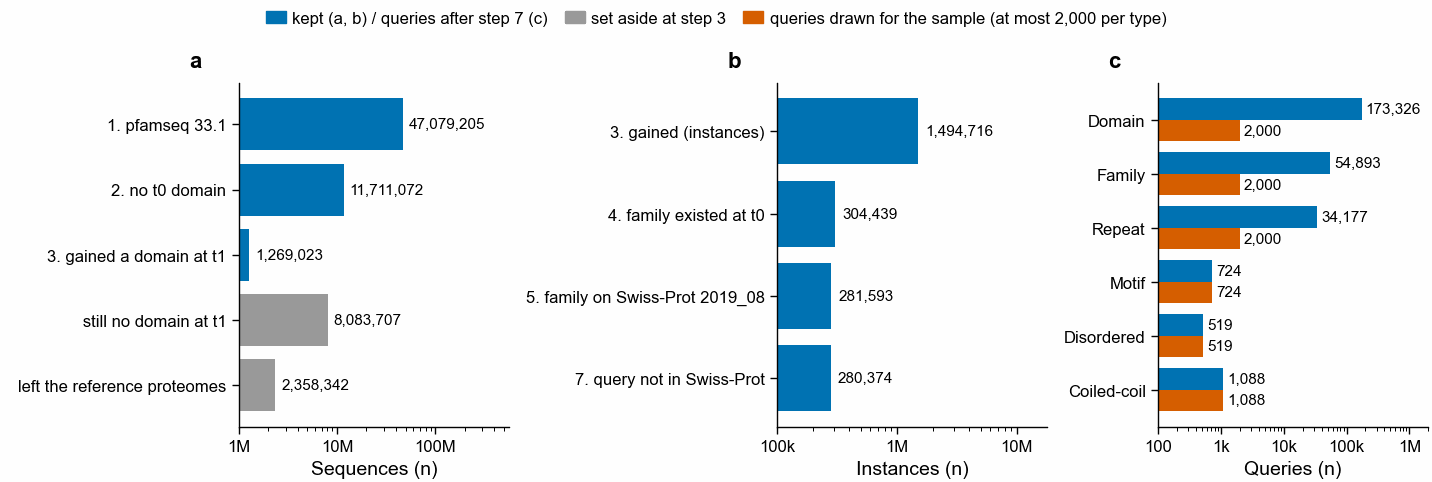

In [2]:
steps_seq = [
    ("1. pfamseq 33.1", FUNNEL.filter(pl.col("step") == "1")["n"][0]),
    ("2. no t0 domain", FUNNEL.filter(pl.col("step") == "2")["n"][0]),
    ("3. gained a domain at t1", FUNNEL.filter(pl.col("step") == "3")["n"][0]),
    ("   still no domain at t1", FUNNEL.filter(pl.col("step") == "3b")["n"][0]),
    ("   left the reference proteomes", FUNNEL.filter(pl.col("step") == "3c")["n"][0]),
]
inst = FUNNEL.filter(
    pl.col("step").is_in(["3", "4", "5", "7"])
    & pl.col("what").str.contains("instances|and the|family existed")
)
steps_inst = [
    ("3. gained (instances)", inst.filter(pl.col("step") == "3")["n"][0]),
    ("4. family existed at t0", inst.filter(pl.col("step") == "4")["n"][0]),
    ("5. family on Swiss-Prot 2019_08", inst.filter(pl.col("step") == "5")["n"][0]),
    ("7. query not in Swiss-Prot", inst.filter(pl.col("step") == "7")["n"][0]),
]
print(pl.DataFrame(steps_seq, schema=["step (sequences)", "n"], orient="row"))
print(pl.DataFrame(steps_inst, schema=["step (instances)", "n"], orient="row"))
print(SAMPLE)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=3)
KEPT, DROPPED, DRAWN = pf.OKABE_ITO["blue"], pf.GREY, pf.OKABE_ITO["vermillion"]
for ax, steps, unit in (
    (axs[0], steps_seq, "Sequences"),
    (axs[1], steps_inst, "Instances"),
):
    labels = [s for s, _ in steps][::-1]
    vals = [v for _, v in steps][::-1]
    colors = [DROPPED if s.startswith("   ") else KEPT for s in labels]
    ax.barh(labels, vals, color=colors)
    ax.set_xscale("log")
    for y, v in enumerate(vals):
        ax.text(v * 1.15, y, f"{v:,}", va="center", fontsize=5.5)
    ax.set_xlim(1e5 if unit == "Instances" else 1e6, max(vals) * 12)
    ax.set_xlabel(f"{unit} (n)")
t = SAMPLE.with_columns(pl.col("pfam_type").cast(pl.Enum(TYPES))).sort(
    "pfam_type", descending=True
)
y = np.arange(t.height)
axs[2].barh(y + 0.2, t["queries_available"], height=0.4, color=KEPT)
axs[2].barh(y - 0.2, t["queries_drawn"], height=0.4, color=DRAWN)
axs[2].set_yticks(y, t["pfam_type"])
axs[2].set_xscale("log")
axs[2].set_xlabel("Queries (n)")
for yy, a, d in zip(y, t["queries_available"], t["queries_drawn"]):
    axs[2].text(a * 1.15, yy + 0.2, f"{a:,}", va="center", fontsize=5.5)
    axs[2].text(d * 1.15, yy - 0.2, f"{d:,}", va="center", fontsize=5.5)
axs[2].set_xlim(100, 2e6)


def plain_count(v, _pos):
    return f"{v / 1e6:g}M" if v >= 1e6 else f"{v / 1e3:g}k" if v >= 1e3 else f"{v:g}"


for ax in axs:
    ax.xaxis.set_major_formatter(FuncFormatter(plain_count))
    ax.xaxis.set_minor_formatter(NullFormatter())
fig.legend(
    handles=[
        Patch(color=KEPT, label="kept (a, b) / queries after step 7 (c)"),
        Patch(color=DROPPED, label="set aside at step 3"),
        Patch(
            color=DRAWN, label="queries drawn for the sample (at most 2,000 per type)"
        ),
    ],
    loc="outside upper center",
    ncol=3,
)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(
    fig, FIG / "time_split_funnel_pfam33-1_to_38-2_sprot2019_08", formats=("png", "pdf")
)

## Stop 1b. Identity of each instance to its closest t0 Swiss-Prot domain

On 500 instances drawn at random (seed 280) from the 280,374 kept at step 7, the query's
t1 domain was aligned with ssearch36 (FASTA 36.3.8i, Smith-Waterman, BLOSUM62, gap open
11, extend 1) to every Swiss-Prot 2019_08 domain of the same family under Pfam 33.1. The
closest is the one with the highest bit score. *Identity* is identical columns divided by
alignment columns, gaps included, as ssearch36 and BLAST report it. Because the alignment
is local, it can cover only part of the domain, so the second reading divides the identical
columns by the whole t1 domain length.

How to read it: P1 predicted that most instances sit below 30% identity. The share left of
the dashed line in panel a answers it. Panel b shows whether the short-feature types that
P4 is about (Motif, Disordered, Repeat) sit at lower or higher identity than Domain and
Family.


shape: (9, 3)
┌──────────────┬─────┬───────┐
│ identity_bin ┆ n   ┆ share │
│ ---          ┆ --- ┆ ---   │
│ str          ┆ i64 ┆ f64   │
╞══════════════╪═════╪═══════╡
│ 0-20%        ┆ 2   ┆ 0.004 │
│ 20-30%       ┆ 93  ┆ 0.186 │
│ 30-40%       ┆ 169 ┆ 0.338 │
│ 40-50%       ┆ 116 ┆ 0.232 │
│ 50-60%       ┆ 68  ┆ 0.136 │
│ 60-70%       ┆ 28  ┆ 0.056 │
│ 70-80%       ┆ 8   ┆ 0.016 │
│ 80-90%       ┆ 10  ┆ 0.02  │
│ 90-100%      ┆ 6   ┆ 0.012 │
└──────────────┴─────┴───────┘
shape: (5, 5)
┌─────────────┬─────┬─────────────────┬─────────────────┬──────────┐
│ pfam_type   ┆ n   ┆ median_identity ┆ median_coverage ┆ under_30 │
│ ---         ┆ --- ┆ ---             ┆ ---             ┆ ---      │
│ str         ┆ i64 ┆ f64             ┆ f64             ┆ f64      │
╞═════════════╪═════╪═════════════════╪═════════════════╪══════════╡
│ Coiled-coil ┆ 5   ┆ 39.58           ┆ 0.866667        ┆ 0.2      │
│ Domain      ┆ 328 ┆ 38.17           ┆ 0.792436        ┆ 0.167683 │
│ Family      ┆ 96  ┆ 32

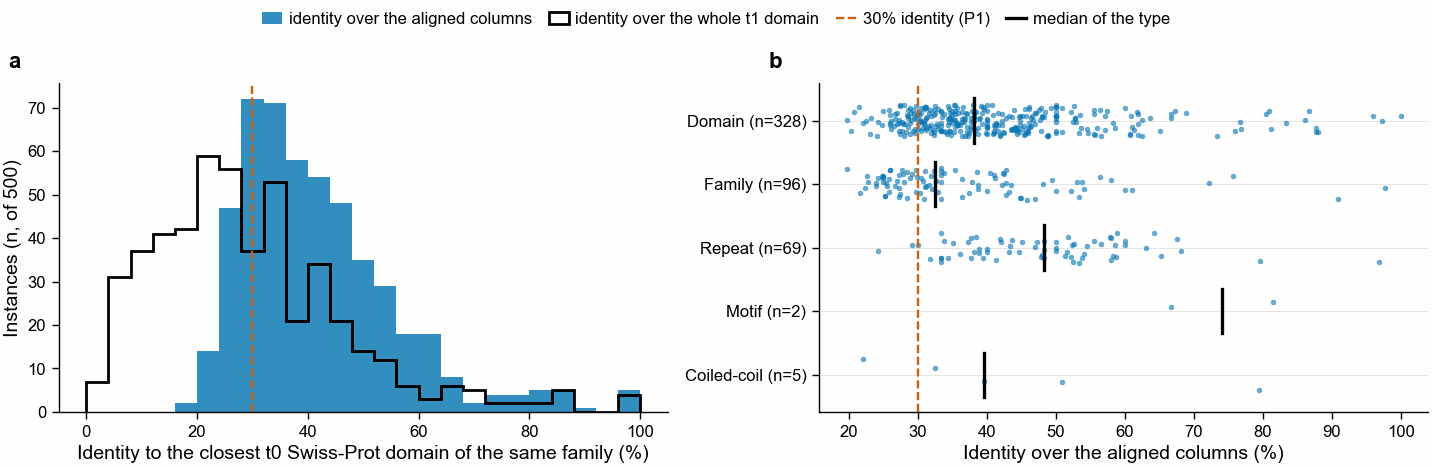

In [3]:
bins = pl.read_csv(STOP1 / "identity_bins.csv")
by_type = pl.read_csv(STOP1 / "identity_by_type.csv")
print(bins)
print(by_type)
n = IDENT.height
under30 = (IDENT["pident"] < 30).sum()
under30_dom = (IDENT["identity_over_domain"] < 30).sum()
print(
    f"identity over the aligned columns: median {IDENT['pident'].median():.1f}%, "
    f"{under30} of {n} under 30% ({100 * under30 / n:.1f}%)"
)
print(
    f"identity over the whole t1 domain: median {IDENT['identity_over_domain'].median():.1f}%, "
    f"{under30_dom} of {n} under 30% ({100 * under30_dom / n:.1f}%)"
)
print(f"aligned share of the t1 domain: median {IDENT['query_coverage'].median():.2f}")

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 60, ncols=2)
edges = np.arange(0, 102, 4)
axs[0].hist(
    IDENT["pident"],
    bins=edges,
    color=pf.OKABE_ITO["blue"],
    alpha=0.8,
    label="identity over the aligned columns",
)
axs[0].hist(
    IDENT["identity_over_domain"],
    bins=edges,
    histtype="step",
    linewidth=1,
    color=pf.OKABE_ITO["black"],
    label="identity over the whole t1 domain",
)
axs[0].axvline(
    30,
    color=pf.OKABE_ITO["vermillion"],
    linestyle="--",
    linewidth=0.8,
    label="30% identity (P1)",
)
axs[0].set_xlabel("Identity to the closest t0 Swiss-Prot domain of the same family (%)")
axs[0].set_ylabel(f"Instances (n, of {n})")
rng = np.random.default_rng(280)
order = [t for t in TYPES if t in IDENT["pfam_type"].unique().to_list()]
for i, t in enumerate(order):
    v = IDENT.filter(pl.col("pfam_type") == t)["pident"].to_numpy()
    axs[1].scatter(
        v,
        i + rng.uniform(-0.25, 0.25, len(v)),
        s=4,
        color=pf.OKABE_ITO["blue"],
        alpha=0.6,
        linewidths=0,
    )
    axs[1].plot(
        [np.median(v)] * 2,
        [i - 0.35, i + 0.35],
        color=pf.OKABE_ITO["black"],
        linewidth=1.2,
        label="median of the type" if i == 0 else None,
    )
axs[1].set_yticks(
    range(len(order)), [f"{t} (n={(IDENT['pfam_type'] == t).sum()})" for t in order]
)
for i in range(len(order)):
    axs[1].axhline(i, color="#dddddd", linewidth=0.3, zorder=0)
axs[1].axvline(30, color=pf.OKABE_ITO["vermillion"], linestyle="--", linewidth=0.8)
axs[1].set_xlabel("Identity over the aligned columns (%)")
axs[1].invert_yaxis()
pf.shared_legend(fig, ncol=4)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(
    fig, FIG / "time_split_identity_500_instances_sprot2019_08", formats=("png", "pdf")
)

## Stop 1c. Five instances as residues

Drawn at random (seed 281) from the 500 above. Each shows the query's t1 domain aligned to
the closest t0 Swiss-Prot domain of the same family (ssearch36 local alignment, so gaps
can appear), a match line and the count, then both in `hp_pbotc_1st_ed2` classes
(h = `ACFILMPVWY`, p = `DEGHKNQRST`) with their own match line. `^` marks the longest run
of columns, with no gap, where both residues are in the same class. kmerseek
`hp_pbotc_1st_ed2` k=19 needs a run of at least 19 such columns to share one k-mer.


In [4]:
print((STOP1 / "five_examples.txt").read_text())

Q23117 (GLoBin related, Eukaryota) t1 PF00042 Globin [Domain] residues 50-166 (117 aa)
closest t0 Swiss-Prot domain: A8XGY6/52-165   bits 43.7
query     50 RCFSRLESNCPIVSQCFQSATY--SLSTNPNGVRTVADHAKYLLQLLDKIIEG-DVDSEF---LREIGANHVCLKHESGFSTQEWDRFQEI 134
               |  ||   | | | |  |              |   | |      |      |   ||    | ||  |  |   | ||   | |  ||
Sprot     73 KIFLELEIASPKVKQIFYKAALVDAFNKDDDNTATLEVHIKLTTKFFDELLATLDDENEFVAKIRGIGSAHAILAKGSNFSSDIWERLGEI 163
27 of 91 aligned columns identical (29.7%)
hp_pbotc_1st_ed2 classes (h = ACFILMPVWY, p = DEGHKNQRST):
query        phhpphppphhhhpphhpphph--phppphpphpphhpphphhhphhpphhpp-phppph---hpphphpphhhppppphpppphpphpph
             ||| |||   | ||||| || |   |||| ||  ||  ||||  ||||||| | | ||||   |||||  |||| |||||||| |||||||
Sprot        phhhphphhphphpphhhphhhhphhppppppphphphphphppphhpphhhphppppphhhphpphpphphhhhpppphppphhpphpph
                                                                                        ^^^^^^^^
64 of 91 columns in 